# 03 · Modeling results

This notebook only **reads** the artifacts written by `early-warning train` (`reports/metrics/`). Training is deliberately kept in versioned code (`src/early_warning/models/train.py`) instead of the notebook, so results are reproducible with one command.

**Setup recap**

| Item | Choice | Why |
|---|---|---|
| Unit | one student × course enrollment (2,964 after excluding final grade = 0) | the outcome is defined per enrollment |
| Targets | `failed` (final < 5, 5.3%) and `final_grade` (0–10) | alert + richer signal |
| Horizons | models at course days 15, 30, 45, 60 | only information available on that day is used |
| Split | 80/20 hold-out **grouped by student**, stratified by failure | students take ~5 courses (ICC ≈ 0.47) |
| Model selection | 5-fold × 3 repeats stratified-grouped CV on train; **one-standard-error rule** | prefer the simplest model when differences are noise |
| Candidates | dummy · logistic/ridge · decision tree · random forest · hist gradient boosting · LightGBM (randomized search) | from interpretable to flexible |
| Classifier post-processing | sigmoid calibration + threshold on out-of-fold predictions for **recall ≥ 0.80** | missing an at-risk student is costlier than a false alarm |
| Test metrics | PR-AUC, ROC-AUC, Brier / MAE, RMSE, R², with **95% CIs from a grouped bootstrap** | 31 failures in test: point estimates alone would mislead |

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve

from early_warning.config import load_config
from early_warning.viz import FAIL, NEUTRAL, PASS, SERIES, save, set_style

set_style()
cfg = load_config()
m = cfg.path("metrics_dir")
comparison = pd.read_csv(m / "model_comparison.csv")
results = json.loads((m / "test_results.json").read_text())
preds = pd.read_csv(m / "test_predictions.csv")
importance = pd.read_csv(m / "feature_importance.csv")
HORIZONS = sorted(comparison["cutoff"].unique())
H_COLORS = dict(zip(HORIZONS, SERIES, strict=False))

## 1. Cross-validated comparison of candidate models

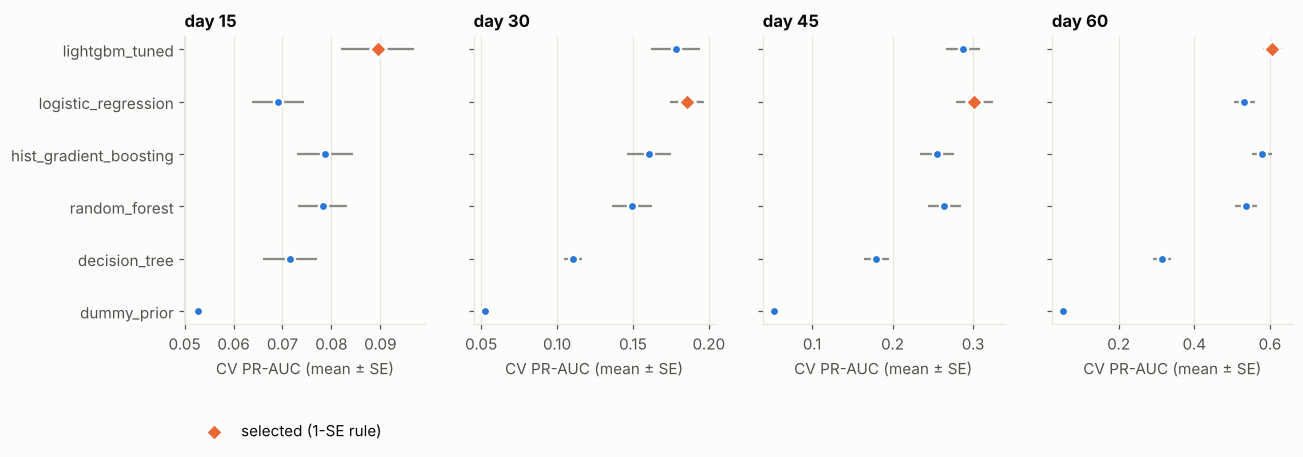

In [2]:
def comparison_plot(task, metric_label, lower_is_better=False):
    d = comparison[comparison.task == task]
    order = d.groupby("model")["mean"].mean().sort_values(ascending=lower_is_better).index[::-1]
    fig, axes = plt.subplots(1, len(HORIZONS), figsize=(13, 3.4), sharey=True)
    for ax, h in zip(axes, HORIZONS, strict=False):
        s = d[d.cutoff == h].set_index("model").reindex(order)
        y = np.arange(len(s))
        ax.hlines(y, s["mean"] - s["se"], s["mean"] + s["se"], color=NEUTRAL, lw=1.5)
        sel = s["selected"].astype(bool).values
        ax.scatter(
            s["mean"][~sel], y[~sel], color=PASS, s=36, zorder=3, edgecolor="white", linewidth=1.5
        )
        ax.scatter(
            s["mean"][sel],
            y[sel],
            color=FAIL,
            s=60,
            zorder=4,
            marker="D",
            edgecolor="white",
            linewidth=1.5,
            label="selected (1-SE rule)",
        )
        ax.set_title(f"day {h}")
        ax.set_yticks(y, s.index)
        ax.grid(axis="x")
        ax.grid(axis="y", visible=False)
        ax.set_xlabel(metric_label)
    axes[0].legend(loc="lower left", bbox_to_anchor=(0, -0.45))
    return fig


fig = comparison_plot("classification", "CV PR-AUC (mean ± SE)")
save(fig, "03_cv_comparison_classification")

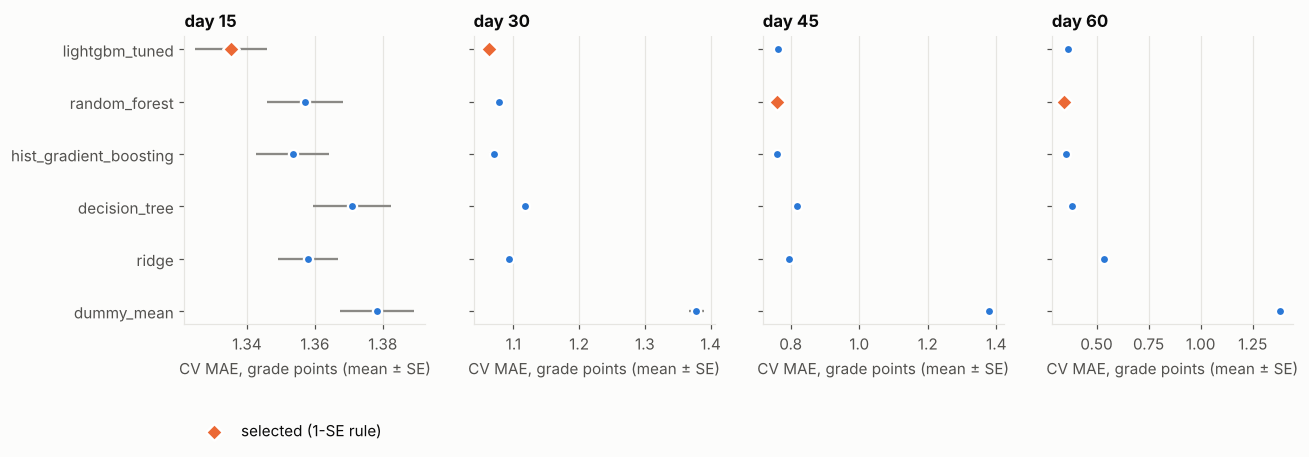

In [3]:
fig = comparison_plot("regression", "CV MAE, grade points (mean ± SE)", lower_is_better=True)
save(fig, "03_cv_comparison_regression")

In [4]:
tbl = comparison.assign(
    score=lambda d: d["mean"].round(3).astype(str) + " ± " + d["se"].round(3).astype(str)
).pivot_table(index=["task", "model"], columns="cutoff", values="score", aggfunc="first")
tbl.columns = [f"day {c}" for c in tbl.columns]
tbl

day 15         day 30  \
task           model                                                  
classification decision_tree           0.072 ± 0.006  0.111 ± 0.006   
               dummy_prior             0.053 ± 0.001  0.053 ± 0.001   
               hist_gradient_boosting  0.079 ± 0.006   0.16 ± 0.015   
               lightgbm_tuned           0.09 ± 0.007  0.178 ± 0.016   
               logistic_regression     0.069 ± 0.005  0.185 ± 0.011   
               random_forest           0.078 ± 0.005  0.149 ± 0.013   
regression     decision_tree           1.371 ± 0.012  1.118 ± 0.007   
               dummy_mean              1.378 ± 0.011  1.378 ± 0.011   
               hist_gradient_boosting  1.353 ± 0.011  1.071 ± 0.007   
               lightgbm_tuned           1.335 ± 0.01  1.063 ± 0.007   
               random_forest           1.357 ± 0.011  1.078 ± 0.007   
               ridge                   1.358 ± 0.009  1.093 ± 0.006   

                                              day 45         day 60  
task           model                                                 
classification decision_tree            0.18 ± 0.016  0.315 ± 0.023  
               dummy_prior             0.053 ± 0.001  0.053 ± 0.001  
               hist_gradient_boosting  0.256 ± 0.021   0.58 ± 0.026  
               lightgbm_tuned          0.287 ± 0.021  0.606 ± 0.025  
               logistic_regression     0.302 ± 0.023  0.532 ± 0.028  
               random_forest           0.264 ± 0.021  0.536 ± 0.029  
regression     decision_tree           0.819 ± 0.007  0.383 ± 0.008  
               dummy_mean              1.378 ± 0.011  1.378 ± 0.011  
               hist_gradient_boosting   0.76 ± 0.009  0.355 ± 0.006  
               lightgbm_tuned          0.763 ± 0.008  0.363 ± 0.007  
               random_forest           0.759 ± 0.009  0.344 ± 0.006  
               ridge                   0.796 ± 0.005  0.534 ± 0.008

**Observations**

* Every candidate beats its dummy baseline at every horizon, but at **day 15** the margin is small (PR-AUC 0.09 vs a 0.053 baseline). Before the first exam, assignment behaviour alone carries little signal.
* At **days 30 and 45** the **logistic regression** wins or ties the boosted trees. With ~125 failures in training, a linear model is as good as a flexible one and is easier to explain, so the 1-SE rule picks it.
* At **day 60** non-linear interactions between exams (best partial, make-ups, integrator) pay off and tuned LightGBM wins clearly.
* For the grade, LightGBM / random forest lead, and the gap to Ridge widens with the horizon (0.53 → 0.34 MAE at day 60).

## 2. Held-out test performance by horizon

In [5]:
rows = []
for r in results:
    for k, v in r["test_metrics"].items():
        rows.append(
            {
                "day": r["cutoff"],
                "task": r["task"],
                "model": r["selected_model"],
                "metric": k,
                "estimate": v["estimate"],
                "ci_low": v["ci95"][0],
                "ci_high": v["ci95"][1],
            }
        )
test = pd.DataFrame(rows)
test.pivot_table(index=["task", "metric"], columns="day", values="estimate").round(3)

day                                  15     30     45     60
task           metric                                       
classification brier              0.049  0.048  0.044  0.032
               pr_auc             0.070  0.150  0.277  0.501
               roc_auc            0.626  0.733  0.865  0.943
regression     mae                1.298  1.055  0.736  0.315
               pr_auc_from_grade  0.089  0.152  0.190  0.460
               r2                 0.067  0.301  0.548  0.808
               rmse               1.642  1.421  1.142  0.744

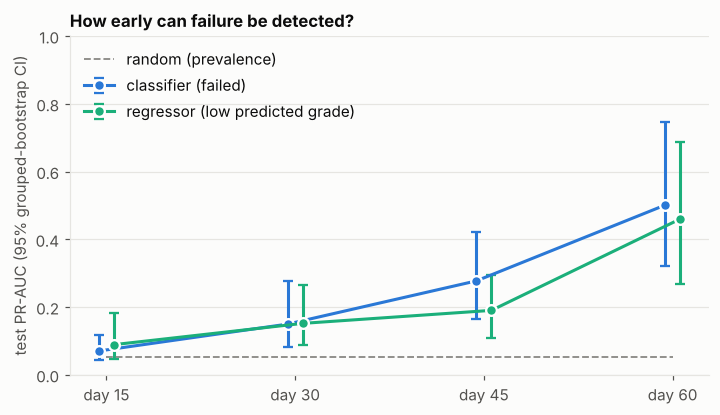

In [6]:
clf = test[(test.task == "classification") & (test.metric == "pr_auc")].set_index("day")
reg = test[(test.task == "regression") & (test.metric == "pr_auc_from_grade")].set_index("day")
prev = {r["cutoff"]: r["prevalence_test"] for r in results if r["task"] == "classification"}

fig, ax = plt.subplots(figsize=(7.5, 4))
for d, color, label, off in [
    (clf, PASS, "classifier (failed)", -0.6),
    (reg, SERIES[2], "regressor (low predicted grade)", 0.6),
]:
    x = d.index + off
    ax.errorbar(
        x,
        d["estimate"],
        yerr=[d["estimate"] - d["ci_low"], d["ci_high"] - d["estimate"]],
        color=color,
        marker="o",
        ms=7,
        capsize=3,
        label=label,
        mec="white",
        mew=1.5,
    )
ax.plot(
    list(prev), list(prev.values()), color=NEUTRAL, ls="--", lw=1.2, label="random (prevalence)"
)
ax.set_xticks(HORIZONS, [f"day {h}" for h in HORIZONS])
ax.set_ylabel("test PR-AUC (95% grouped-bootstrap CI)")
ax.set_ylim(0, 1)
ax.set_title("How early can failure be detected?")
ax.legend(loc="upper left")
save(fig, "03_performance_by_horizon")

* Detection quality **rises sharply once exam grades exist** (days 30 → 45 → 60).
* Ranking students by a *predicted grade* is similar to the classifier early on, but clearly worse once exams exist (day 45: 0.19 vs 0.28). The regressor optimizes the whole 0–10 range, where most students are, while the alert is about the tail, so the alert uses the dedicated classifier.
* The CIs are wide (31 failures in test), so neighbouring horizons should not be over-interpreted.

## 3. Operating point: what an alert means in practice

In [7]:
op = pd.DataFrame(
    [
        {"day": r["cutoff"], "model": r["selected_model"], **r["operating_point_test"]}
        for r in results
        if r["task"] == "classification"
    ]
).set_index("day")
op["students flagged per 100"] = (op["alert_rate"] * 100).round(1)
op["true failures caught per 100 flagged"] = (op["precision"] * 100).round(1)
op[
    [
        "model",
        "threshold",
        "recall",
        "precision",
        "f1",
        "students flagged per 100",
        "true failures caught per 100 flagged",
    ]
].round(3)

,model,threshold,recall,precision,f1,students flagged per 100,true failures caught per 100 flagged
day,,,,,,,
15,lightgbm_tuned,0.043,0.871,0.066,0.122,69.5,6.6
30,logistic_regression,0.046,0.774,0.086,0.154,47.2,8.6
45,logistic_regression,0.063,0.774,0.173,0.282,23.4,17.3
60,lightgbm_tuned,0.095,0.742,0.324,0.451,12.0,32.4


The threshold is fixed on **training out-of-fold predictions** to target 80% recall, and the test set confirms it reaches ~74–87%. The cost of that recall is the alert volume. On day 15 the model has to flag ~70% of students to catch most failures, so it is not useful as an alert. On **day 45 it flags ~23% of students, and 17% of them really fail, more than 3× the base rate**, and on day 60 it flags ~12% with one real failure in three.

**Recommended use:** a *staged* system. Day 30 gives a broad, low-cost nudge (an automated email or a tutor check-in); day 45 triggers a targeted intervention. Days 15 and 60 are kept for monitoring only: day 15 is too noisy, and on day 60 it is too late to act.

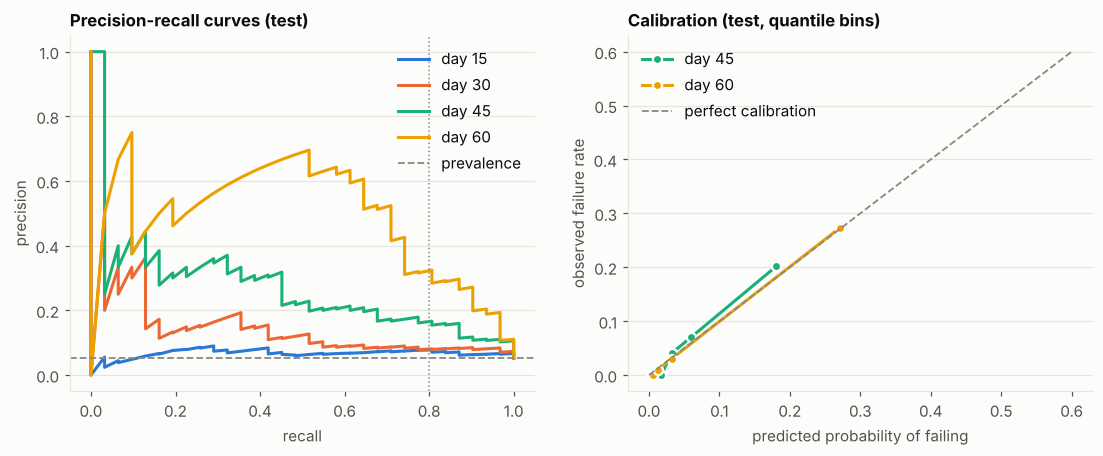

In [8]:
c = preds[preds.task == "classification"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
for h in HORIZONS:
    d = c[c.cutoff == h]
    p, r, _ = precision_recall_curve(d["failed"], d["prediction"])
    ax.plot(r, p, color=H_COLORS[h], label=f"day {h}")
ax.axhline(c["failed"].mean(), color=NEUTRAL, ls="--", lw=1.2, label="prevalence")
ax.axvline(cfg.training["target_recall"], color=NEUTRAL, ls=":", lw=1)
ax.set_xlabel("recall")
ax.set_ylabel("precision")
ax.set_title("Precision-recall curves (test)")
ax.legend(loc="upper right")

ax = axes[1]
for h in [45, 60]:
    d = c[c.cutoff == h]
    frac, mean_pred = calibration_curve(d["failed"], d["prediction"], n_bins=6, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", color=H_COLORS[h], label=f"day {h}", mec="white", mew=1.5)
ax.plot([0, 0.6], [0, 0.6], color=NEUTRAL, ls="--", lw=1.2, label="perfect calibration")
ax.set_xlabel("predicted probability of failing")
ax.set_ylabel("observed failure rate")
ax.set_title("Calibration (test, quantile bins)")
ax.legend(loc="upper left")
save(fig, "03_pr_and_calibration")

## 4. What drives the predictions? (permutation importance on test)

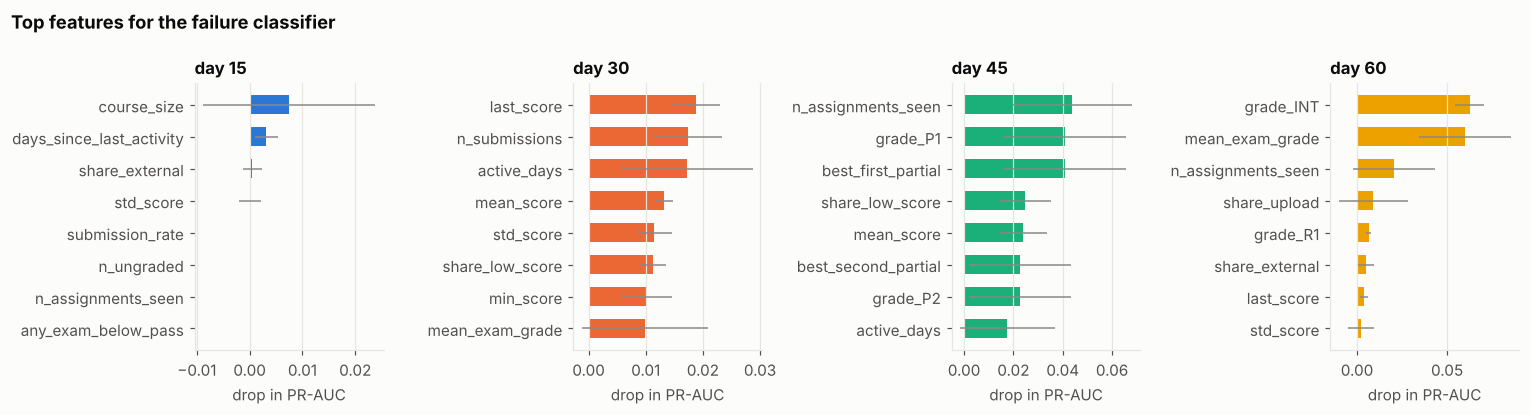

In [9]:
imp = importance[importance.task == "classification"]
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(14, 3.8))
for ax, h in zip(axes, HORIZONS, strict=False):
    d = imp[imp.cutoff == h].nlargest(8, "importance_mean").iloc[::-1]
    ax.barh(
        d["feature"],
        d["importance_mean"],
        xerr=d["importance_std"],
        color=H_COLORS[h],
        height=0.6,
        error_kw={"ecolor": NEUTRAL, "lw": 1},
    )
    ax.set_title(f"day {h}")
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("drop in PR-AUC")
fig.suptitle("Top features for the failure classifier", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "03_feature_importance")

The ranking follows the course calendar. Early on, the model relies on assignment behaviour (scores, submission volume and rate). Once the first partial happens, exam features take over, and by day 60 the model is close to the institution's grading rule. Some importances are near zero with large error bars, a reminder that the test set has only 31 failures.

## 5. Grade regression

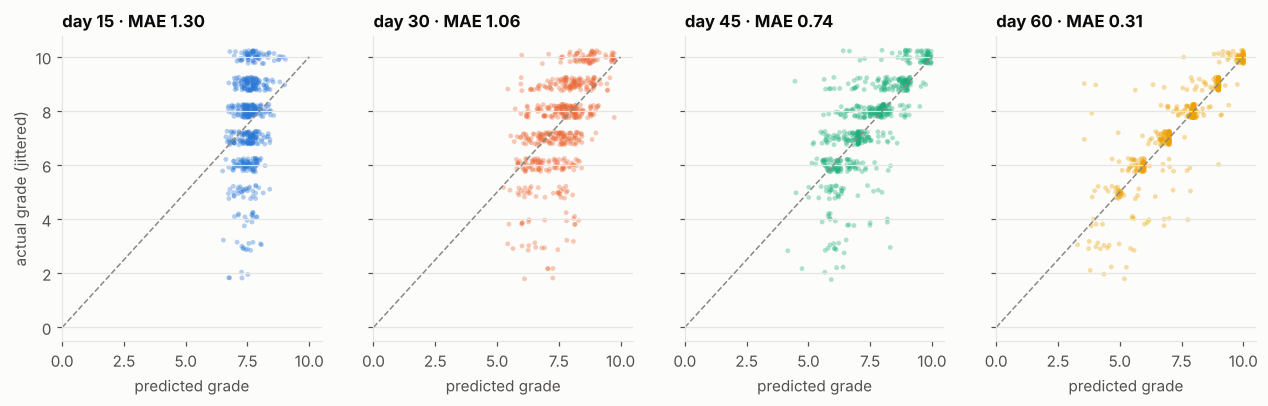

In [10]:
r = preds[preds.task == "regression"]
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(14, 3.6), sharey=True)
rng = np.random.default_rng(0)
for ax, h in zip(axes, HORIZONS, strict=False):
    d = r[r.cutoff == h]
    jitter = rng.uniform(-0.25, 0.25, len(d))
    ax.scatter(
        d["prediction"],
        d["final_grade"] + jitter,
        s=10,
        alpha=0.35,
        color=H_COLORS[h],
        edgecolor="none",
    )
    ax.plot([0, 10], [0, 10], color=NEUTRAL, ls="--", lw=1)
    mae = test[(test.task == "regression") & (test.metric == "mae") & (test.day == h)][
        "estimate"
    ].iloc[0]
    ax.set_title(f"day {h} · MAE {mae:.2f}")
    ax.set_xlabel("predicted grade")
    ax.set_xlim(0, 10.5)
axes[0].set_ylabel("actual grade (jittered)")
save(fig, "03_regression_pred_vs_actual")

## 6. Final model and justification

| Horizon | Deployed classifier | Deployed regressor | Rationale |
|---|---|---|---|
| Day 15 | tuned LightGBM | tuned LightGBM | best CV, but barely above baseline: **monitoring only** |
| Day 30 | **logistic regression** | tuned LightGBM | linear model ties/beats boosting (1-SE rule) and is explainable to tutors through its coefficients |
| Day 45 | **logistic regression** | random forest | same as day 30; best precision-for-recall trade-off among actionable horizons |
| Day 60 | tuned LightGBM | random forest | non-linear exam interactions matter; useful for analytics, too late for intervention |

All classifiers are calibrated, so their probabilities can be read as risk (Brier 0.03–0.05). The served API picks, for a request on day *d*, the latest model trained at a horizon ≤ *d*, so a prediction never uses information that does not exist yet.

**Limitations.** (1) Small number of failures, hence wide CIs; (2) almost a single semester of data, so there is no out-of-time validation. The first production step should be to re-validate on the next cohort. (3) Exams dominate, so behaviour-only signals are weak before the first partial.